In [63]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [64]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [65]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [66]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [67]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


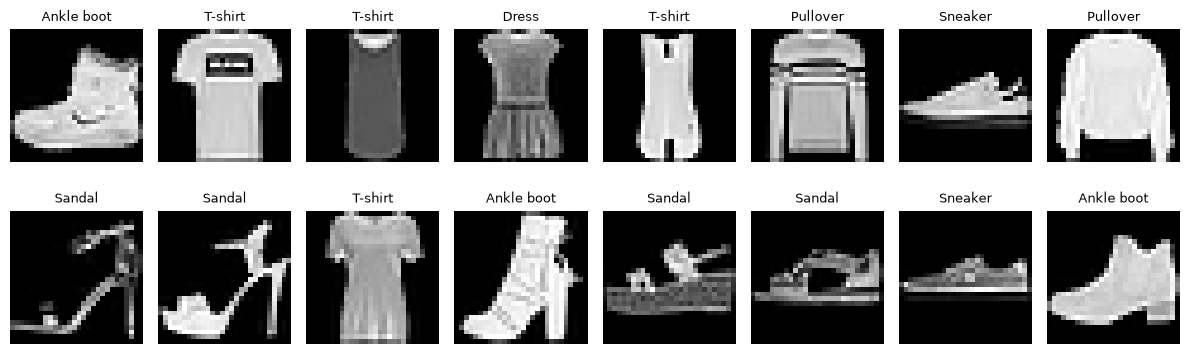

In [68]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Learning Rate

In [ ]:
import math
## different LR change functions

def constant(epoch):
    return 0.1

def step_decay(epoch):
    return 0.1 * 0.5 **(epoch//8)


def exponentail_decay(epoch):
    return 0.1 * math.exp(-0.1*epoch)


epochs = range(32)
plt.plot(epochs, [constant(epoch) for epoch in epochs], label='constant')
plt.plot(epochs, [step_decay(epoch) for epoch in epochs], label='step_decay')
plt.plot(epochs, [exponentail_decay(epoch) for epoch in epochs], label='exponentail_decay')
plt.legend()
plt.show()

In [ ]:
def make_model():
    model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for schedule in [constant, step_decay, exponentail_decay]:
    model = make_model()
    lr_callback = keras.callbacks.LearningRateScheduler(schedule=schedule)
    history = model.fit(x_train, y_train, validation_split=0.2, epochs=30, 
                        batch_size=32, callbacks=[lr_callback], verbose=0)
    print(f"{schedule.__name__}: test_accuracy: {model.evaluate(x_test, y_test, verbose=0)}")
    plt.plot(history.history["loss"], label={schedule.__name__})

plt.legend()
plt.show()